In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("Housing.csv")
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Shape:", df.shape)
print()
df.info()
print()
print("Nulls per column:")
print(df.isnull().sum())

Shape: (545, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Nulls per column:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroa

In [3]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


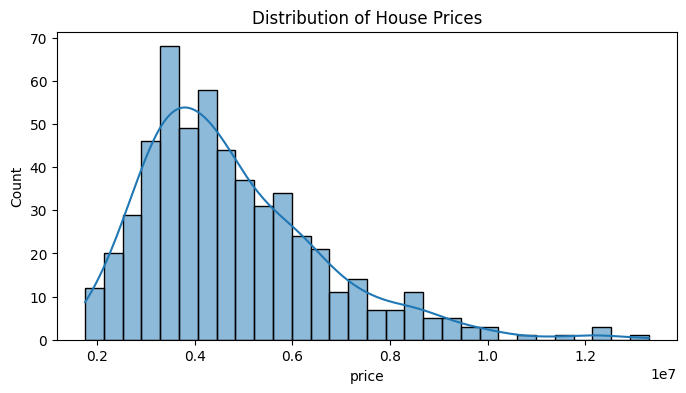

In [4]:
plt.figure(figsize=(8,4))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.show()

## Initial Data Inspection

The dataset has 545 houses and 13 columns, with no missing values. Six columns are numeric (price, area, bedrooms, bathrooms, stories, parking) and seven are categorical (six yes/no columns and furnishingstatus).

House prices are right-skewed: the mean (~4.77M) is above the median (~4.34M), most houses cost between about 3M and 6M, and a small number of expensive houses stretch the range up to 13.3M. Area is also spread widely, from 1,650 to 16,200.

This dataset has no location or house-age column. The closest thing to location is `prefarea` (preferred area).

## Feature Selection Discussion

Before building the model, I looked at which features are likely to predict house price. This is my starting hypothesis, and I check it against the correlation heatmap later.

**Likely strong predictors**
- `area`: larger houses usually cost more.
- `bathrooms` and `stories`: more bathrooms and floors usually mean a bigger, more expensive house.
- `airconditioning` and `parking`: these are comfort features that buyers tend to pay extra for.
- `prefarea`: houses in a preferred area should have a price premium. This is the closest thing to a location variable, because the dataset has no location or house-age column.

**Likely weaker predictors**
- `hotwaterheating`: only 25 of the 545 houses have it, so there is little data to learn from.
- `guestroom` and `basement`: these are less common, and I expect a smaller effect on price.

**Possible problem: multicollinearity**
Some features probably move together. For example, houses with more bedrooms often have more bathrooms and stories. When predictors overlap like this, linear regression can split their effect in unstable ways, so individual coefficients may be unreliable even if the overall predictions are good. I will interpret the coefficients with caution.

**Encoding plan**
The six yes/no columns will be converted to 1/0, and `furnishingstatus` (furnished, semi-furnished, unfurnished) will be one-hot encoded.

## Encoding Categorical Features

The six yes/no columns (mainroad, guestroom, basement, hotwaterheating, airconditioning, prefarea) were mapped to 1 and 0. `furnishingstatus` has three values, so it was one-hot encoded into separate columns. I used `drop_first=True`, which removes the `furnished` column. Furnished is now the baseline category, and the two remaining columns show how semi-furnished and unfurnished houses differ from it. This avoids redundant columns, because the third one can always be worked out from the other two.

In [5]:
binary_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]

df_enc = df.copy()
for c in binary_cols:
    df_enc[c] = df_enc[c].map({"yes": 1, "no": 0})

df_enc = pd.get_dummies(df_enc, columns=["furnishingstatus"], drop_first=True, dtype=int)
df_enc.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


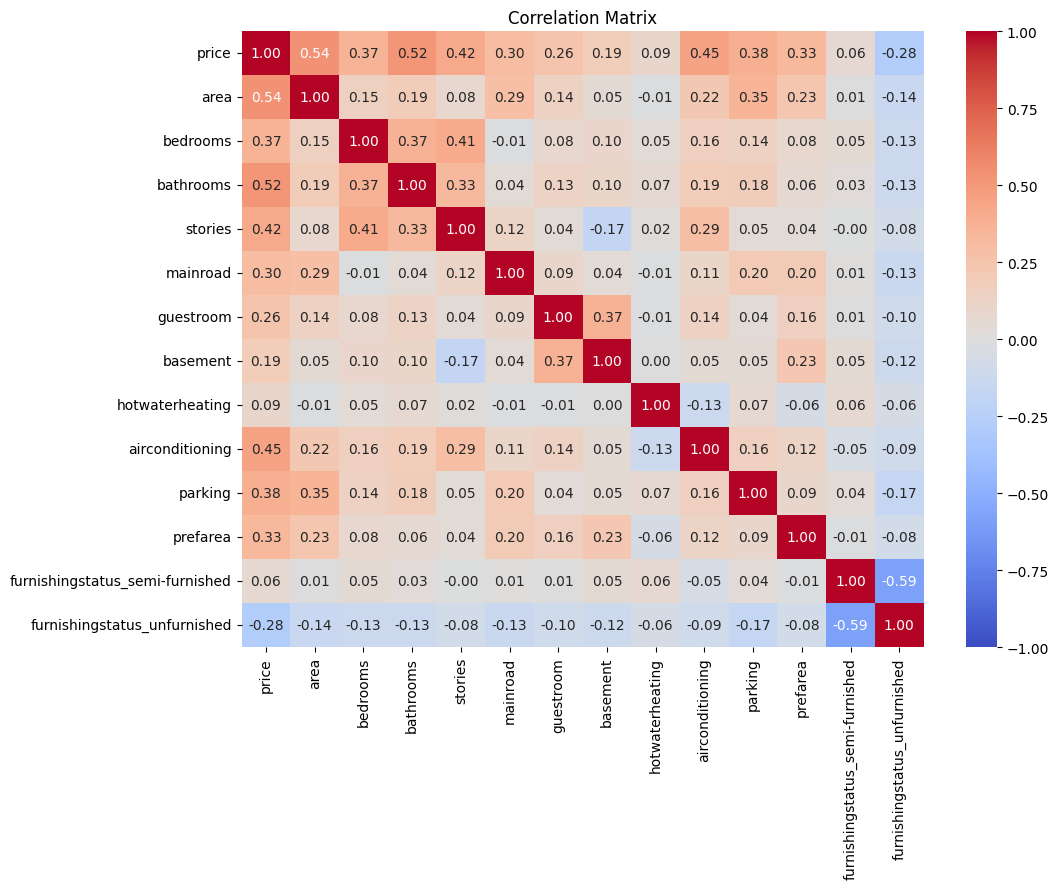

price                              1.00
area                               0.54
bathrooms                          0.52
airconditioning                    0.45
stories                            0.42
parking                            0.38
bedrooms                           0.37
prefarea                           0.33
mainroad                           0.30
guestroom                          0.26
basement                           0.19
hotwaterheating                    0.09
furnishingstatus_semi-furnished    0.06
furnishingstatus_unfurnished      -0.28
Name: price, dtype: float64


In [6]:
plt.figure(figsize=(11,8))
sns.heatmap(df_enc.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

print(df_enc.corr()["price"].sort_values(ascending=False).round(2))

## Correlation Analysis

The features most correlated with price are area (0.54), bathrooms (0.52), air conditioning (0.45), stories (0.42) and parking (0.38). Unfurnished houses have a negative correlation with price (-0.28), so they tend to be cheaper than furnished ones. Hot water heating (0.09) and semi-furnished status (0.06) have almost no linear relationship with price.

No single feature has a correlation above 0.54, so price depends on a combination of factors. My earlier hypothesis held up: area, bathrooms and air conditioning are among the strongest predictors, and hot water heating is weak.

There is also some overlap between predictors: bedrooms correlates with stories (0.41) and bathrooms (0.37), and guestroom with basement (0.37). This multicollinearity can make individual coefficients less reliable, so I will interpret them with caution.

In [7]:
from sklearn.model_selection import train_test_split

X = df_enc.drop("price", axis=1)
y = df_enc["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (436, 13) | Test: (109, 13)


## Train/Test Split

I split the data 80/20 with a fixed random seed (random_state=42). That gives 436 houses for training and 109 for testing. The model never sees the test houses while it learns, so the test score shows how well it predicts new houses.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE : {mse:,.0f}")
print(f"RMSE: {rmse:,.0f}")
print(f"R2  : {r2:.3f}")

MSE : 1,754,318,687,331
RMSE: 1,324,507
R2  : 0.653


## Model Evaluation

| Metric | Value |
|---|---|
| MSE | 1,754,318,687,331 |
| RMSE | 1,324,507 |
| R² | 0.653 |

The model explains about 65% of the variation in house prices on unseen data. A typical prediction is off by about 1.3M, which is roughly 28% of the average price (4.77M). This is a reasonable baseline, but not very precise.

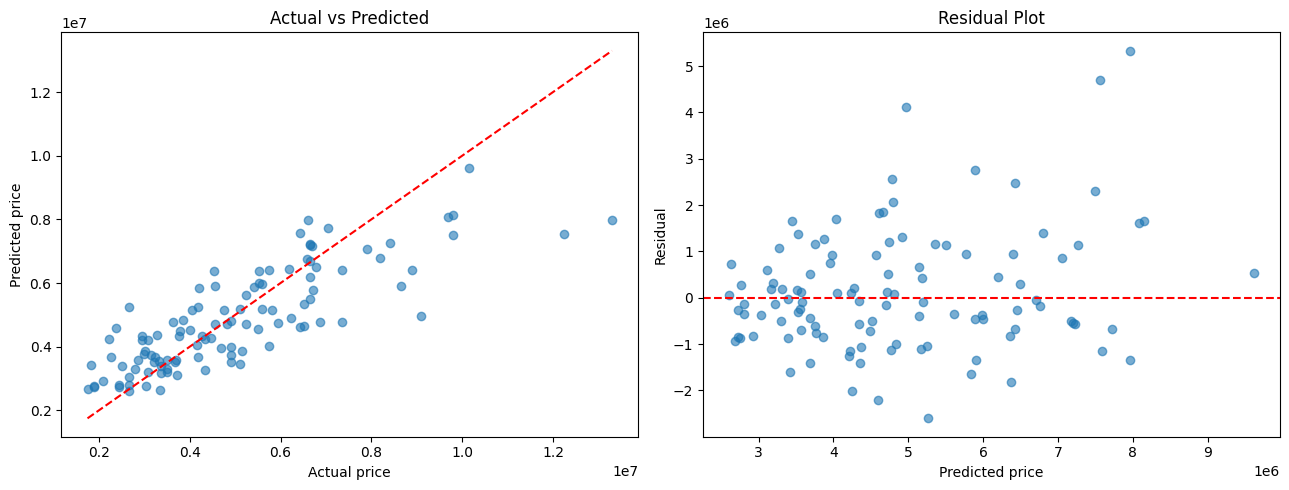

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13,5))

ax[0].scatter(y_test, y_pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual price")
ax[0].set_ylabel("Predicted price")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.6)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted price")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residual Plot")
plt.tight_layout()
plt.show()

## Actual vs Predicted and Residuals

In the actual vs predicted plot, cheaper and mid-priced houses (up to about 7M) sit fairly close to the diagonal line. For expensive houses the model predicts too low, and the most expensive house (13.3M) is predicted at only about 8M.

The residuals are centred around zero, but they are not perfectly random. They spread out as the predicted price goes up, and the biggest errors are under-predictions of expensive houses. So the linear model does not fully capture the high end of the market. Using a log of price, or a different model, might help.

In [10]:
coef = pd.Series(model.coef_, index=X.columns).sort_values(ascending=False)
print(coef.round(0))

bathrooms                          1094445.0
airconditioning                     791427.0
hotwaterheating                     684650.0
prefarea                            629891.0
stories                             407477.0
basement                            390251.0
mainroad                            367920.0
guestroom                           231610.0
parking                             224842.0
bedrooms                             76779.0
area                                   236.0
furnishingstatus_semi-furnished    -126882.0
furnishingstatus_unfurnished       -413645.0
dtype: float64


## Coefficient Analysis

Bathrooms (+1.09M per extra bathroom), air conditioning (+0.79M) and preferred area (+0.63M) have the largest positive effects on price. Unfurnished houses are about 0.41M cheaper than furnished ones (the baseline).

A few points need caution:
- Area has a small coefficient (+236) only because it is measured in large units. It still has the strongest correlation with price (0.54), so a small coefficient does not mean it is unimportant.
- Hot water heating has a large coefficient (+0.68M), but only 25 houses have it, so this estimate is unreliable.
- Bedrooms has a small coefficient (+77K), probably because it overlaps with bathrooms and stories (multicollinearity).

## Conclusion

A linear regression model trained on 545 houses reached an R² of 0.653 and an RMSE of about 1.32M on the test set. Bathrooms, air conditioning, preferred area and furnishing status had the clearest effects on price.

**Limitations:**
- The model under-predicts expensive houses, and the errors grow with price.
- The dataset has no location or house-age information, and only 545 houses.
- Some features overlap (multicollinearity), so individual coefficients should be read with caution.

**Possible improvements:** log-transform the price, standardise the features, or try Ridge, Lasso or tree-based models.